In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

In [3]:
TICKER_1 = "EWA"
TICKER_2 = "EWC"
START = "2000-01-01"
END = "2020-01-01"

prices = yf.download([TICKER_1, TICKER_2], start=START, end=END)
close = prices["Close"][[TICKER_1, TICKER_2]].dropna()
log_x = np.log(close[TICKER_1])
log_y = np.log(close[TICKER_2])

/tmp/ipykernel_3760/4285891799.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download([TICKER_1, TICKER_2], start=START, end=END)
[*********************100%***********************]  2 of 2 completed


In [4]:
# Define algorithm parameters
REGRESSION_WINDOW = 252
ZSCORE_WINDOW = 20
ENTRY_THRESHOLD = 1.0
EXIT_THRESHOLD = 0.75

In [5]:
def rolling_ols(x: pd.Series, y: pd.Series, window: int) -> tuple[pd.Series, pd.Series]:
    """Return intercept and slope available at each date, using prior data only."""
    x_prev = x.shift(1)
    y_prev = y.shift(1)
    mean_x = x_prev.rolling(window, min_periods=window).mean()
    mean_y = y_prev.rolling(window, min_periods=window).mean()
    covariance = x_prev.rolling(window, min_periods=window).cov(y_prev)
    variance = x_prev.rolling(window, min_periods=window).var()
    beta = covariance / variance
    alpha = mean_y - beta * mean_x
    return alpha, beta

In [6]:
# Parameters at t are estimated through t-1. The residual at t therefore
# uses today's observed prices but no future observations.
alpha, beta = rolling_ols(log_x, log_y, REGRESSION_WINDOW)
spread = log_y - (alpha + beta * log_x)

In [7]:
# Standardize the current spread against the prior ZSCORE_WINDOW spreads.
prior_spread = spread.shift(1)
rolling_mean = prior_spread.rolling(ZSCORE_WINDOW, min_periods=ZSCORE_WINDOW).mean()
rolling_std = prior_spread.rolling(ZSCORE_WINDOW, min_periods=ZSCORE_WINDOW).std()
z_score = (spread - rolling_mean) / rolling_std.replace(0, np.nan)

In [9]:
position = 0
positions, entries, exits = [], [], []

for z in z_score:
  entry = exit_ = 0
  if pd.notna(z):

    # ENTRY RULES
    if position == 0:
      if z < -ENTRY_THRESHOLD:
        position, entry = 1, 1
      elif z > ENTRY_THRESHOLD:
        position, entry = -1, -1

    # EXIT RULES
    elif position == 1 and z > -EXIT_THRESHOLD:
      position, exit_ = 0, 1
    elif position == -1 and z < EXIT_THRESHOLD:
      position, exit_ = 0, -1
  positions.append(position)
  entries.append(entry)
  exits.append(exit_)

signals = pd.DataFrame(
    {"position": positions, "entry": entries, "exit": exits},
    index=z_score.index,
)

In [10]:
results = close.join(
    pd.DataFrame(
        {
            "alpha": alpha,
            "beta": beta,
            "spread": spread,
            "z_score": z_score,
        }
    )
).join(signals)

In [11]:
# The close-t signal is held over t+1. Use the hedge ratio known at close t
# to size the pair for that same next-day holding period.
asset_returns = close.pct_change()
next_period_beta = beta.shift(1)
gross_exposure = 1 + next_period_beta.abs()
weight_1 = 1 / gross_exposure
weight_2 = next_period_beta / gross_exposure
pair_return = weight_1 * asset_returns[TICKER_2] - weight_2 * asset_returns[TICKER_1]
results["strategy_return"] = results["position"].shift(1) * pair_return
results["cumulative_strategy"] = (1 + results["strategy_return"].fillna(0)).cumprod()

benchmark = (1 + asset_returns[[TICKER_1, TICKER_2]].mean(axis=1)).cumprod()

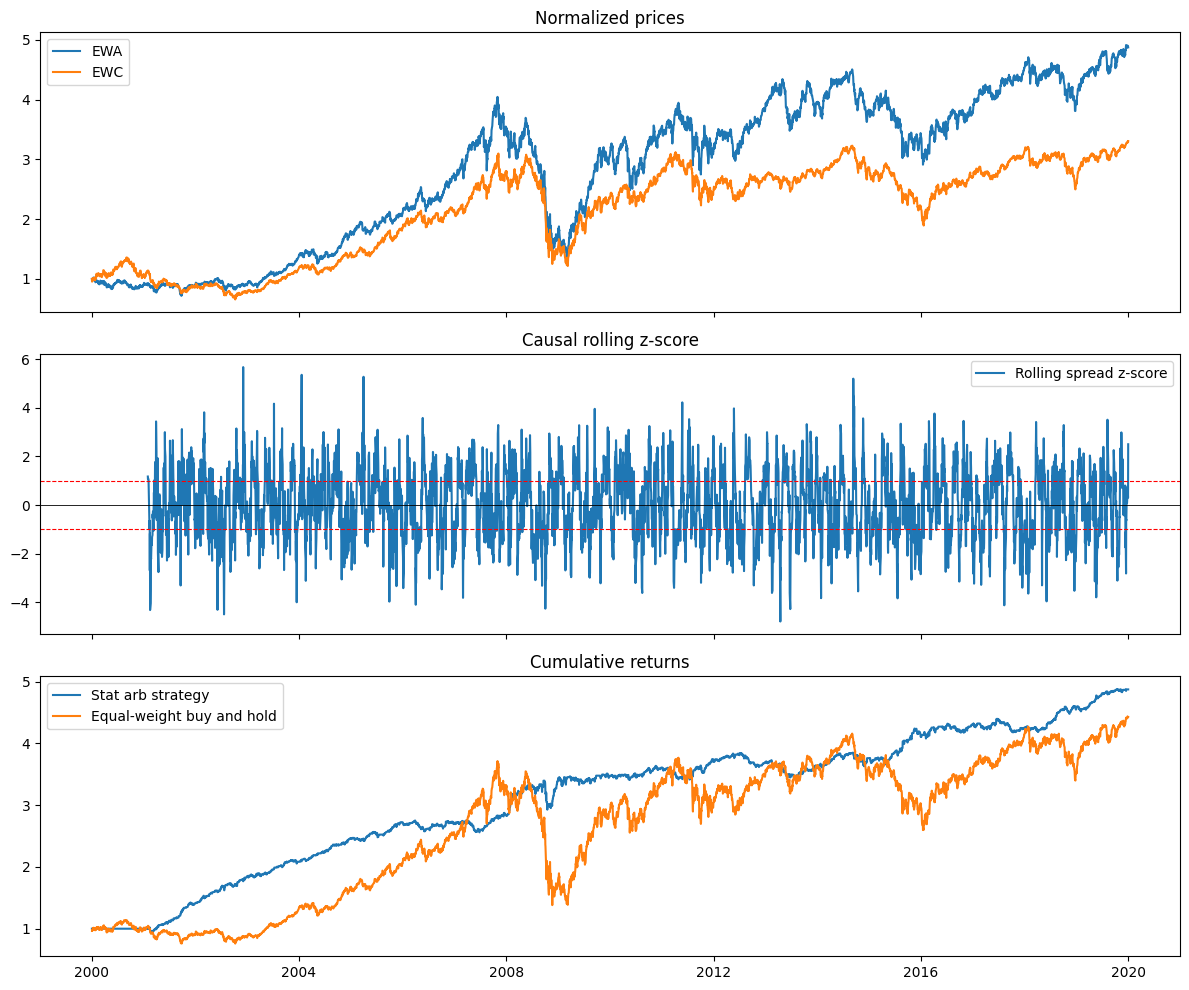

In [12]:
# Plot results
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
axes[0].plot(close[TICKER_1] / close[TICKER_1].iloc[0], label=TICKER_1)
axes[0].plot(close[TICKER_2] / close[TICKER_2].iloc[0], label=TICKER_2)
axes[0].set_title("Normalized prices")
axes[0].legend()

axes[1].plot(results["z_score"], label="Rolling spread z-score")
axes[1].axhline(ENTRY_THRESHOLD, color="red", linestyle="--", linewidth=0.8)
axes[1].axhline(-ENTRY_THRESHOLD, color="red", linestyle="--", linewidth=0.8)
axes[1].axhline(0, color="black", linewidth=0.6)
axes[1].set_title("Causal rolling z-score")
axes[1].legend()

axes[2].plot(results["cumulative_strategy"], label="Stat arb strategy")
axes[2].plot(benchmark, label="Equal-weight buy and hold")
axes[2].set_title("Cumulative returns")
axes[2].legend(loc="upper left")
fig.tight_layout()
plt.show()

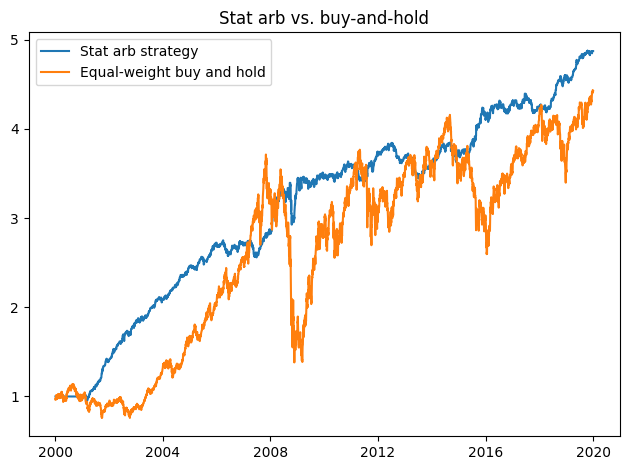

In [14]:
plt.plot(results["cumulative_strategy"], label="Stat arb strategy")
plt.plot(benchmark, label="Equal-weight buy and hold")
plt.title("Stat arb vs. buy-and-hold")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()